Momento de inercia equivalente:
J = 0.1605 kg*m^2

Simulación completada correctamente.

Resultados finales:
Posición final = 29.1842 rad
Posición final = 1672.1289 grados
Velocidad final = 3.6306 rad/s


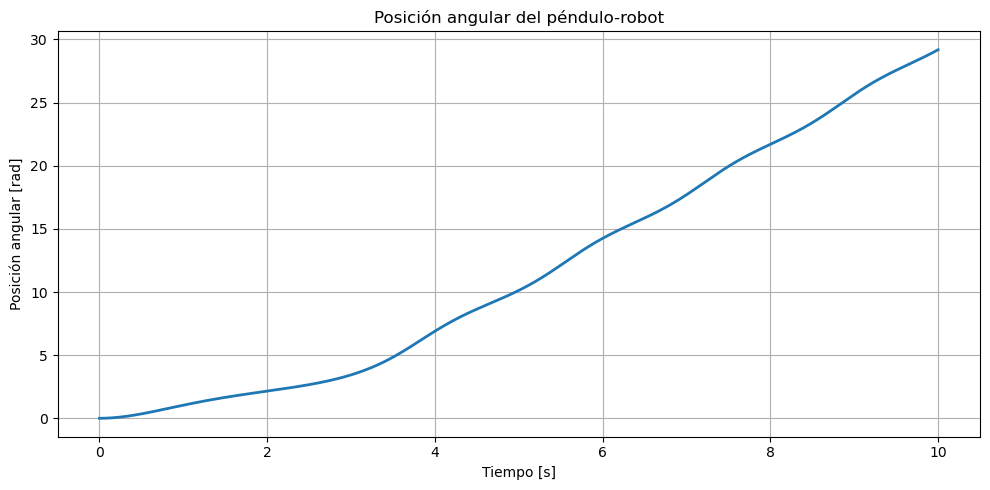

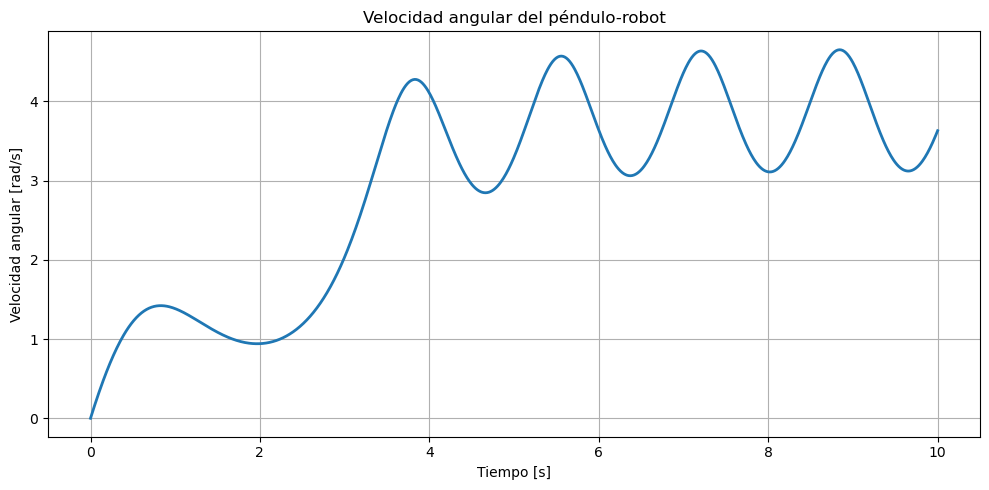

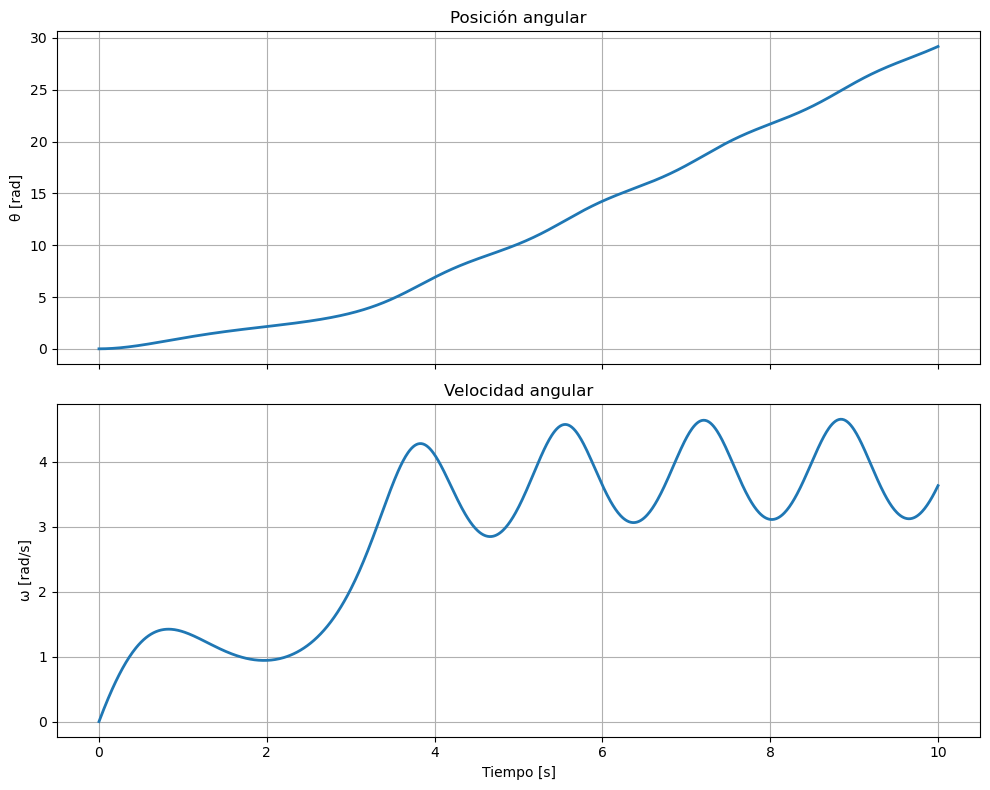

In [1]:
# ============================================================
# AF 3 - Simulación numérica e interpretación del
# comportamiento dinámico del péndulo-robot
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# ============================================================
# 1. PARÁMETROS DEL SISTEMA
# ============================================================

Ir = 0.16       # Momento de inercia del rotor [kg*m^2]
m = 5.0         # Masa del mecanismo [kg]
g = 9.81        # Gravedad [m/s^2]
lc = 0.01       # Distancia al centro de masa [m]
b = 0.14        # Coeficiente de viscosidad [N*m*s/rad]
fc = 0.45       # Fricción de Coulomb [N*m]

# Par aplicado por el motor
# Este valor puede modificarse para realizar diferentes pruebas
tau_entrada = 1.0       # [N*m]

# ============================================================
# 2. MOMENTO DE INERCIA EQUIVALENTE
# ============================================================

J = Ir + m * (lc ** 2)

print("Momento de inercia equivalente:")
print(f"J = {J:.4f} kg*m^2")

# ============================================================
# 3. MODELO DINÁMICO EN ESPACIO DE ESTADOS
# ============================================================

def robot_pendulo(t, x):

    # Estados
    x1 = x[0]       # Posición angular [rad]
    x2 = x[1]       # Velocidad angular [rad/s]

    # Ecuación de posición
    dx1 = x2

    # Fricción de Coulomb
    friccion = fc * np.sign(x2)

    # Ecuación dinámica
    dx2 = (
        tau_entrada
        - b * x2
        - friccion
        - m * g * lc * np.sin(x1)
    ) / J

    return [dx1, dx2]


# ============================================================
# 4. CONDICIONES INICIALES
# ============================================================

# X1 = posición angular inicial
# X2 = velocidad angular inicial

x0 = [0.0, 0.0]

# ============================================================
# 5. TIEMPO DE SIMULACIÓN
# ============================================================

t_inicio = 0
t_final = 10

t_span = (t_inicio, t_final)

# Puntos donde se evaluará la solución
t_eval = np.linspace(t_inicio, t_final, 1000)

# ============================================================
# 6. SOLUCIÓN NUMÉRICA
# ============================================================

solucion = solve_ivp(
    robot_pendulo,
    t_span,
    x0,
    t_eval=t_eval,
    method='RK45',
    rtol=1e-8,
    atol=1e-10,
    max_step=0.01
)

# Verificar que el solucionador terminó correctamente
if solucion.success:
    print("\nSimulación completada correctamente.")
else:
    print("\nError durante la simulación:")
    print(solucion.message)


# ============================================================
# 7. OBTENER LOS RESULTADOS
# ============================================================

tiempo = solucion.t

posicion = solucion.y[0]       # X1 [rad]
velocidad = solucion.y[1]      # X2 [rad/s]

# Conversión opcional de posición a grados
posicion_grados = np.rad2deg(posicion)


# ============================================================
# 8. RESULTADOS FINALES
# ============================================================

print("\nResultados finales:")
print(f"Posición final = {posicion[-1]:.4f} rad")
print(f"Posición final = {posicion_grados[-1]:.4f} grados")
print(f"Velocidad final = {velocidad[-1]:.4f} rad/s")


# ============================================================
# 9. GRÁFICA DE POSICIÓN
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    tiempo,
    posicion,
    linewidth=2
)

plt.title("Posición angular del péndulo-robot")
plt.xlabel("Tiempo [s]")
plt.ylabel("Posición angular [rad]")
plt.grid(True)

plt.tight_layout()
plt.show()


# ============================================================
# 10. GRÁFICA DE VELOCIDAD
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    tiempo,
    velocidad,
    linewidth=2
)

plt.title("Velocidad angular del péndulo-robot")
plt.xlabel("Tiempo [s]")
plt.ylabel("Velocidad angular [rad/s]")
plt.grid(True)

plt.tight_layout()
plt.show()


# ============================================================
# 11. GRÁFICA CONJUNTA
# ============================================================

fig, ax = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

# Posición
ax[0].plot(
    tiempo,
    posicion,
    linewidth=2
)

ax[0].set_title("Posición angular")
ax[0].set_ylabel("θ [rad]")
ax[0].grid(True)

# Velocidad
ax[1].plot(
    tiempo,
    velocidad,
    linewidth=2
)

ax[1].set_title("Velocidad angular")
ax[1].set_xlabel("Tiempo [s]")
ax[1].set_ylabel("ω [rad/s]")
ax[1].grid(True)

plt.tight_layout()
plt.show()